In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.compose import ColumnTransformer






In [ ]:
df = pd.read_csv('dataset/Student_Performance.csv')
df.head()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Unnamed: 0                        10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [7]:
df.shape

(10000, 6)

In [8]:
df.describe()

,Unnamed: 0,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [9]:
df.columns

Index(['Unnamed: 0', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [10]:
df.duplicated().sum()

np.int64(132)

In [11]:
df = df.drop_duplicates().copy()

In [12]:
df.isnull().sum().sort_values(ascending=False)

Sample Question Papers Practiced    2778
Extracurricular Activities          1563
Previous Scores                        0
Unnamed: 0                             0
Sleep Hours                            0
Performance Index                      0
dtype: int64

In [13]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='most_frequent')

impute.fit(df[['Extracurricular Activities']])

df[['Extracurricular Activities']] = impute.transform(
    df[['Extracurricular Activities']]
)

In [14]:
print(df.columns.tolist())

['Unnamed: 0', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


In [15]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='median')

df[['Sample Question Papers Practiced']] = impute.fit_transform(
    df[['Sample Question Papers Practiced']]
)

In [16]:
#df.drop(['Sample Question Papers Practiced'],axis=1,inplace=True)

In [17]:
df.isnull().sum()

Unnamed: 0                          0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

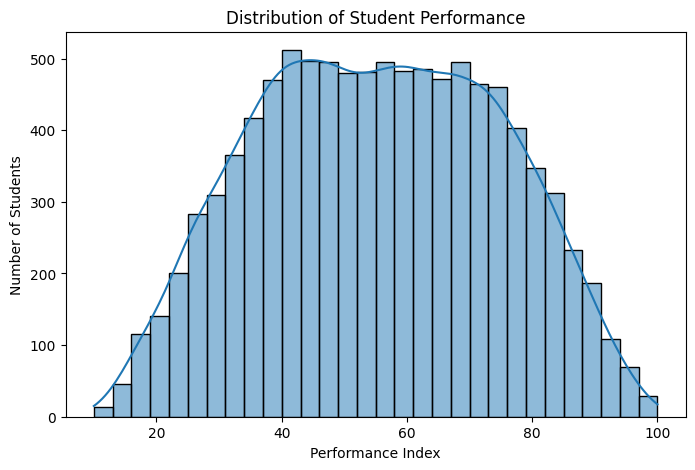

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Performance Index",
    bins=30,
    kde=True
)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Index")
plt.ylabel("Number of Students")
plt.show()

In [20]:
df.columns = df.columns.str.strip()

In [ ]:
plt.figure(figsize=(8, 5))
#sns.scatterplot(data=df, x='Hours_Studied', y='Performance_Index')
#plt.title('Performance_Index vs Hours_Studied')
plt.tight_layout()
plt.show()

<Axes: >

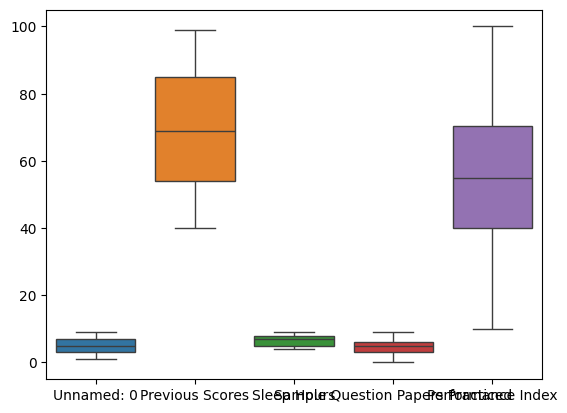

In [24]:
sns.boxplot(df)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. قراءة الملف مع حذف المسافات التلقائية
df = pd.read_csv(
    'dataset/Student_Performance.csv',
    skipinitialspace=True,
)

# 2. تنظيف أسماء الأعمدة من أي مسافات زائدة في البداية والنهاية
df.columns = df.columns.str.strip()

# 3. التأكد من الأسماء الفعلية في الـ DataFrame
print('أسماء الأعمدة المتاحة حالياً:')
print(df.columns.tolist())

In [28]:
print(list(df.columns))

['Unnamed: 0', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


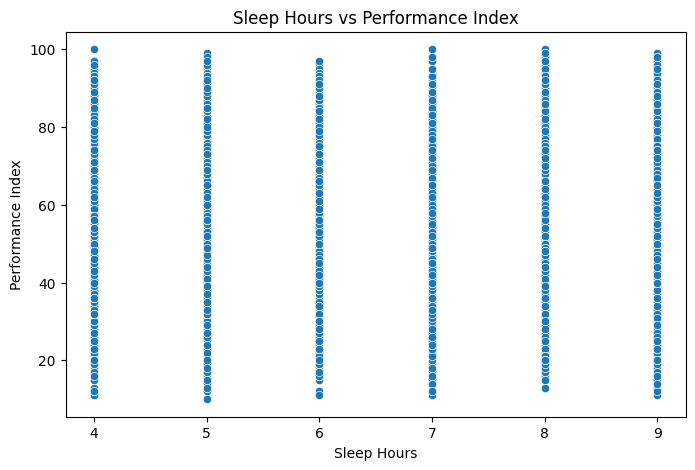

In [29]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sleep Hours', y='Performance Index')
plt.title('Sleep Hours vs Performance Index')
plt.xlabel('Sleep Hours')
plt.ylabel('Performance Index')
plt.show()

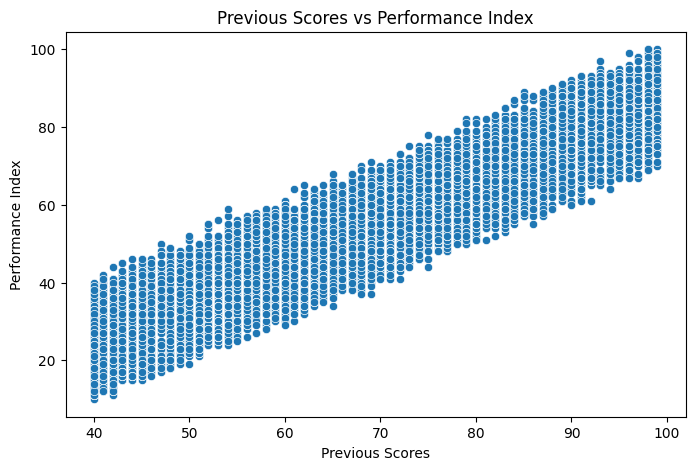

In [30]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Previous Scores', y='Performance Index')
plt.title('Previous Scores vs Performance Index')
plt.xlabel('Previous Scores')
plt.ylabel('Performance Index')
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x='Previous Scores',y='Performance Index',hue='Extracurricular Activities')
plt.title('Performance Index vs Previous Scores')
plt.tight_layout()
plt.show()

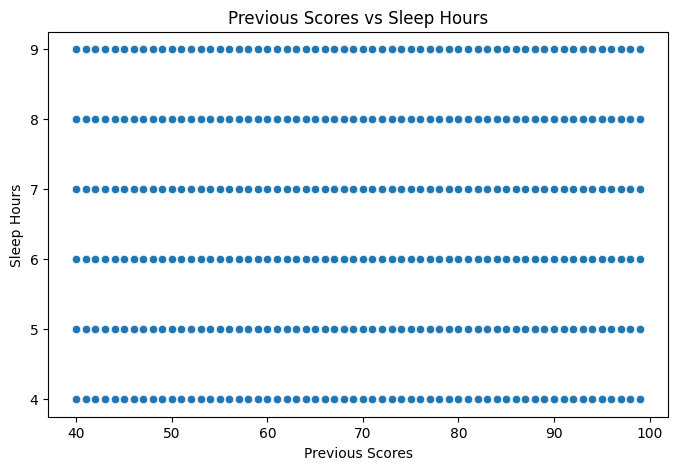

In [33]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Previous Scores",
    y="Sleep Hours"
)
plt.title("Previous Scores vs Sleep Hours")
plt.xlabel("Previous Scores")
plt.ylabel("Sleep Hours")
plt.show()

In [34]:
from sklearn.preprocessing import OneHotEncoder

In [35]:
onehotencoder = OneHotEncoder()

In [36]:
onehotencoder.fit_transform(df[['Extracurricular Activities']])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10000 stored elements and shape (10000, 3)>

In [ ]:
import pandas as pd

# 1. قراءة الملف الأصلي
df = pd.read_csv('dataset/Student_Performance.csv')

# 2. تنظيف أسماء الأعمدة من أي مسافات زائدة
df.columns = df.columns.str.strip()

# 3. التأكد من وجود كل الأعمدة
print(df.columns.tolist())

In [ ]:
import pandas as pd

# 1. قراءة الملف وتسوية العناوين
df = pd.read_csv(
    'dataset/Student_Performance.csv',
    skipinitialspace=True,
)
df.columns = df.columns.str.strip()

# 2. تحويل عمود Extracurricular Activities من نصوص (Yes/No) لأرقام (1/0)
if 'Extracurricular Activities' in df.columns:
    df['Extracurricular Activities'] = (
        df['Extracurricular Activities'].map({'Yes': 1, 'No': 0}).fillna(0)
    )

# 3. اختيار كل الأعمدة الرقمية الموجودة في الملف عدا الهدف (Performance Index)
X = df.drop(
    columns=['Performance Index', 'Unnamed: 0'], errors='ignore'
).select_dtypes(include=['number'])
y = df['Performance Index'].copy()

print('الأعمدة اللي اتدخلت في X بنجاح:')
print(X.columns.tolist())
print('\nشكل X:', X.shape)
print('شكل y:', y.shape)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [44]:
encoder = ColumnTransformer(
    transformers=[
        ('onehot',
         OneHotEncoder(handle_unknown='ignore'),
         ['Extracurricular Activities'])
    ],
    remainder='passthrough'
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)


In [48]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression


imputer = SimpleImputer(strategy='mean')


X_train_clean = imputer.fit_transform(X_train_encoded)
X_test_clean = imputer.transform(X_test_encoded)


model = LinearRegression()
model.fit(X_train_clean, y_train)


print('R2 Score:', model.score(X_test_clean, y_test))

R2 Score: 0.8435143915906982


In [50]:

y_train_pred = model.predict(X_train_clean)
y_test_pred = model.predict(X_test_clean)


print('Train R2 Score:', r2_score(y_train, y_train_pred))
print('Test R2 Score:', r2_score(y_test, y_test_pred))
print('Test MSE:', mean_squared_error(y_test, y_test_pred))

Train R2 Score: 0.8396003682834569
Test R2 Score: 0.8435143915906982
Test MSE: 57.991237344691704


In [51]:
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2 Score: {test_r2:.4f}")

MAE: 6.5265
RMSE: 7.6152
R2 Score: 0.8435


In [65]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import (
    AdaBoostRegressor,
    BaggingRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# 1. تجهيز الداتا وتنظيف العمود النصي وحذف أي Unnamed index
if 'Extracurricular Activities' in df.columns:
  df['Extracurricular Activities'] = (
      df['Extracurricular Activities'].map({'Yes': 1, 'No': 0}).fillna(0)
  )

# حذف عمود الإندكس غير المرغوب فيه لو موجود
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# 2. تقسيم الـ X والـ y
X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. معالجة القيم المفقودة (Imputation) للحماية من أخطاء الـ NaN
imputer = SimpleImputer(strategy='mean')
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns
)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

# 4. عمل Scaling للبيانات النظيفة
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# 5. تعريف النماذج
models = {
    'Linear Regression': LinearRegression(),
    'Lasso': Lasso(),
    'Ridge': Ridge(),
    'KNN': KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),
    'SVM': SVR(kernel='rbf', C=100, gamma=1),
    'Decision Tree': DecisionTreeRegressor(
        criterion='squared_error', max_depth=10
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=50, criterion='squared_error', max_depth=10, random_state=42
    ),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=100, random_state=42),
    'Bagging': BaggingRegressor(
        estimator=DecisionTreeRegressor(
            criterion='squared_error', max_depth=10
        ),
        n_estimators=15,
        random_state=42,
    ),
    'AdaBoost': AdaBoostRegressor(n_estimators=15, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.1, random_state=42
    ),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    'CatBoost': CatBoostRegressor(
        verbose=0, iterations=100, learning_rate=0.1, random_state=42
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
}

results = []
all_preds = {}

# 6. تدريب وتقييم كافة النماذج
for name, model in models.items():
  # استخدام البيانات المُنظّفة والمقيسة للنماذج التي تتأثر بالنطاق العددي
  if name in ['Linear Regression', 'Lasso', 'Ridge', 'KNN', 'SVM']:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
  else:
    model.fit(X_train_imp, y_train)
    y_pred = model.predict(X_test_imp)

  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_test, y_pred)

  all_preds[name] = y_pred
  results.append({
      'Model': name,
      'MAE': mae,
      'MSE': mse,
      'RMSE': rmse,
      'R2 Score': r2,
  })

# 7. عرض جدول النتائج مرتباً من الأفضل للأقل حسب R2 Score
results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000098 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 79
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 3
[LightGBM] [Info] Start training from score 55.311500


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,6.529358,58.134579,7.624604,0.843128
1,Ridge,6.529358,58.134891,7.624624,0.843127
2,CatBoost,6.541943,58.582698,7.653933,0.841918
3,GradientBoosting,6.549756,58.760591,7.665546,0.841438
4,LightGBM,6.592023,59.988648,7.745234,0.838125
5,HistGradientBoosting,6.592322,59.992578,7.745488,0.838114
6,Lasso,6.587223,60.141394,7.755088,0.837712
7,AdaBoost,6.623254,60.762326,7.795019,0.836037
8,SVM,6.610011,60.804358,7.797715,0.835923
9,XGBoost,6.641150,61.228954,7.824893,0.834778


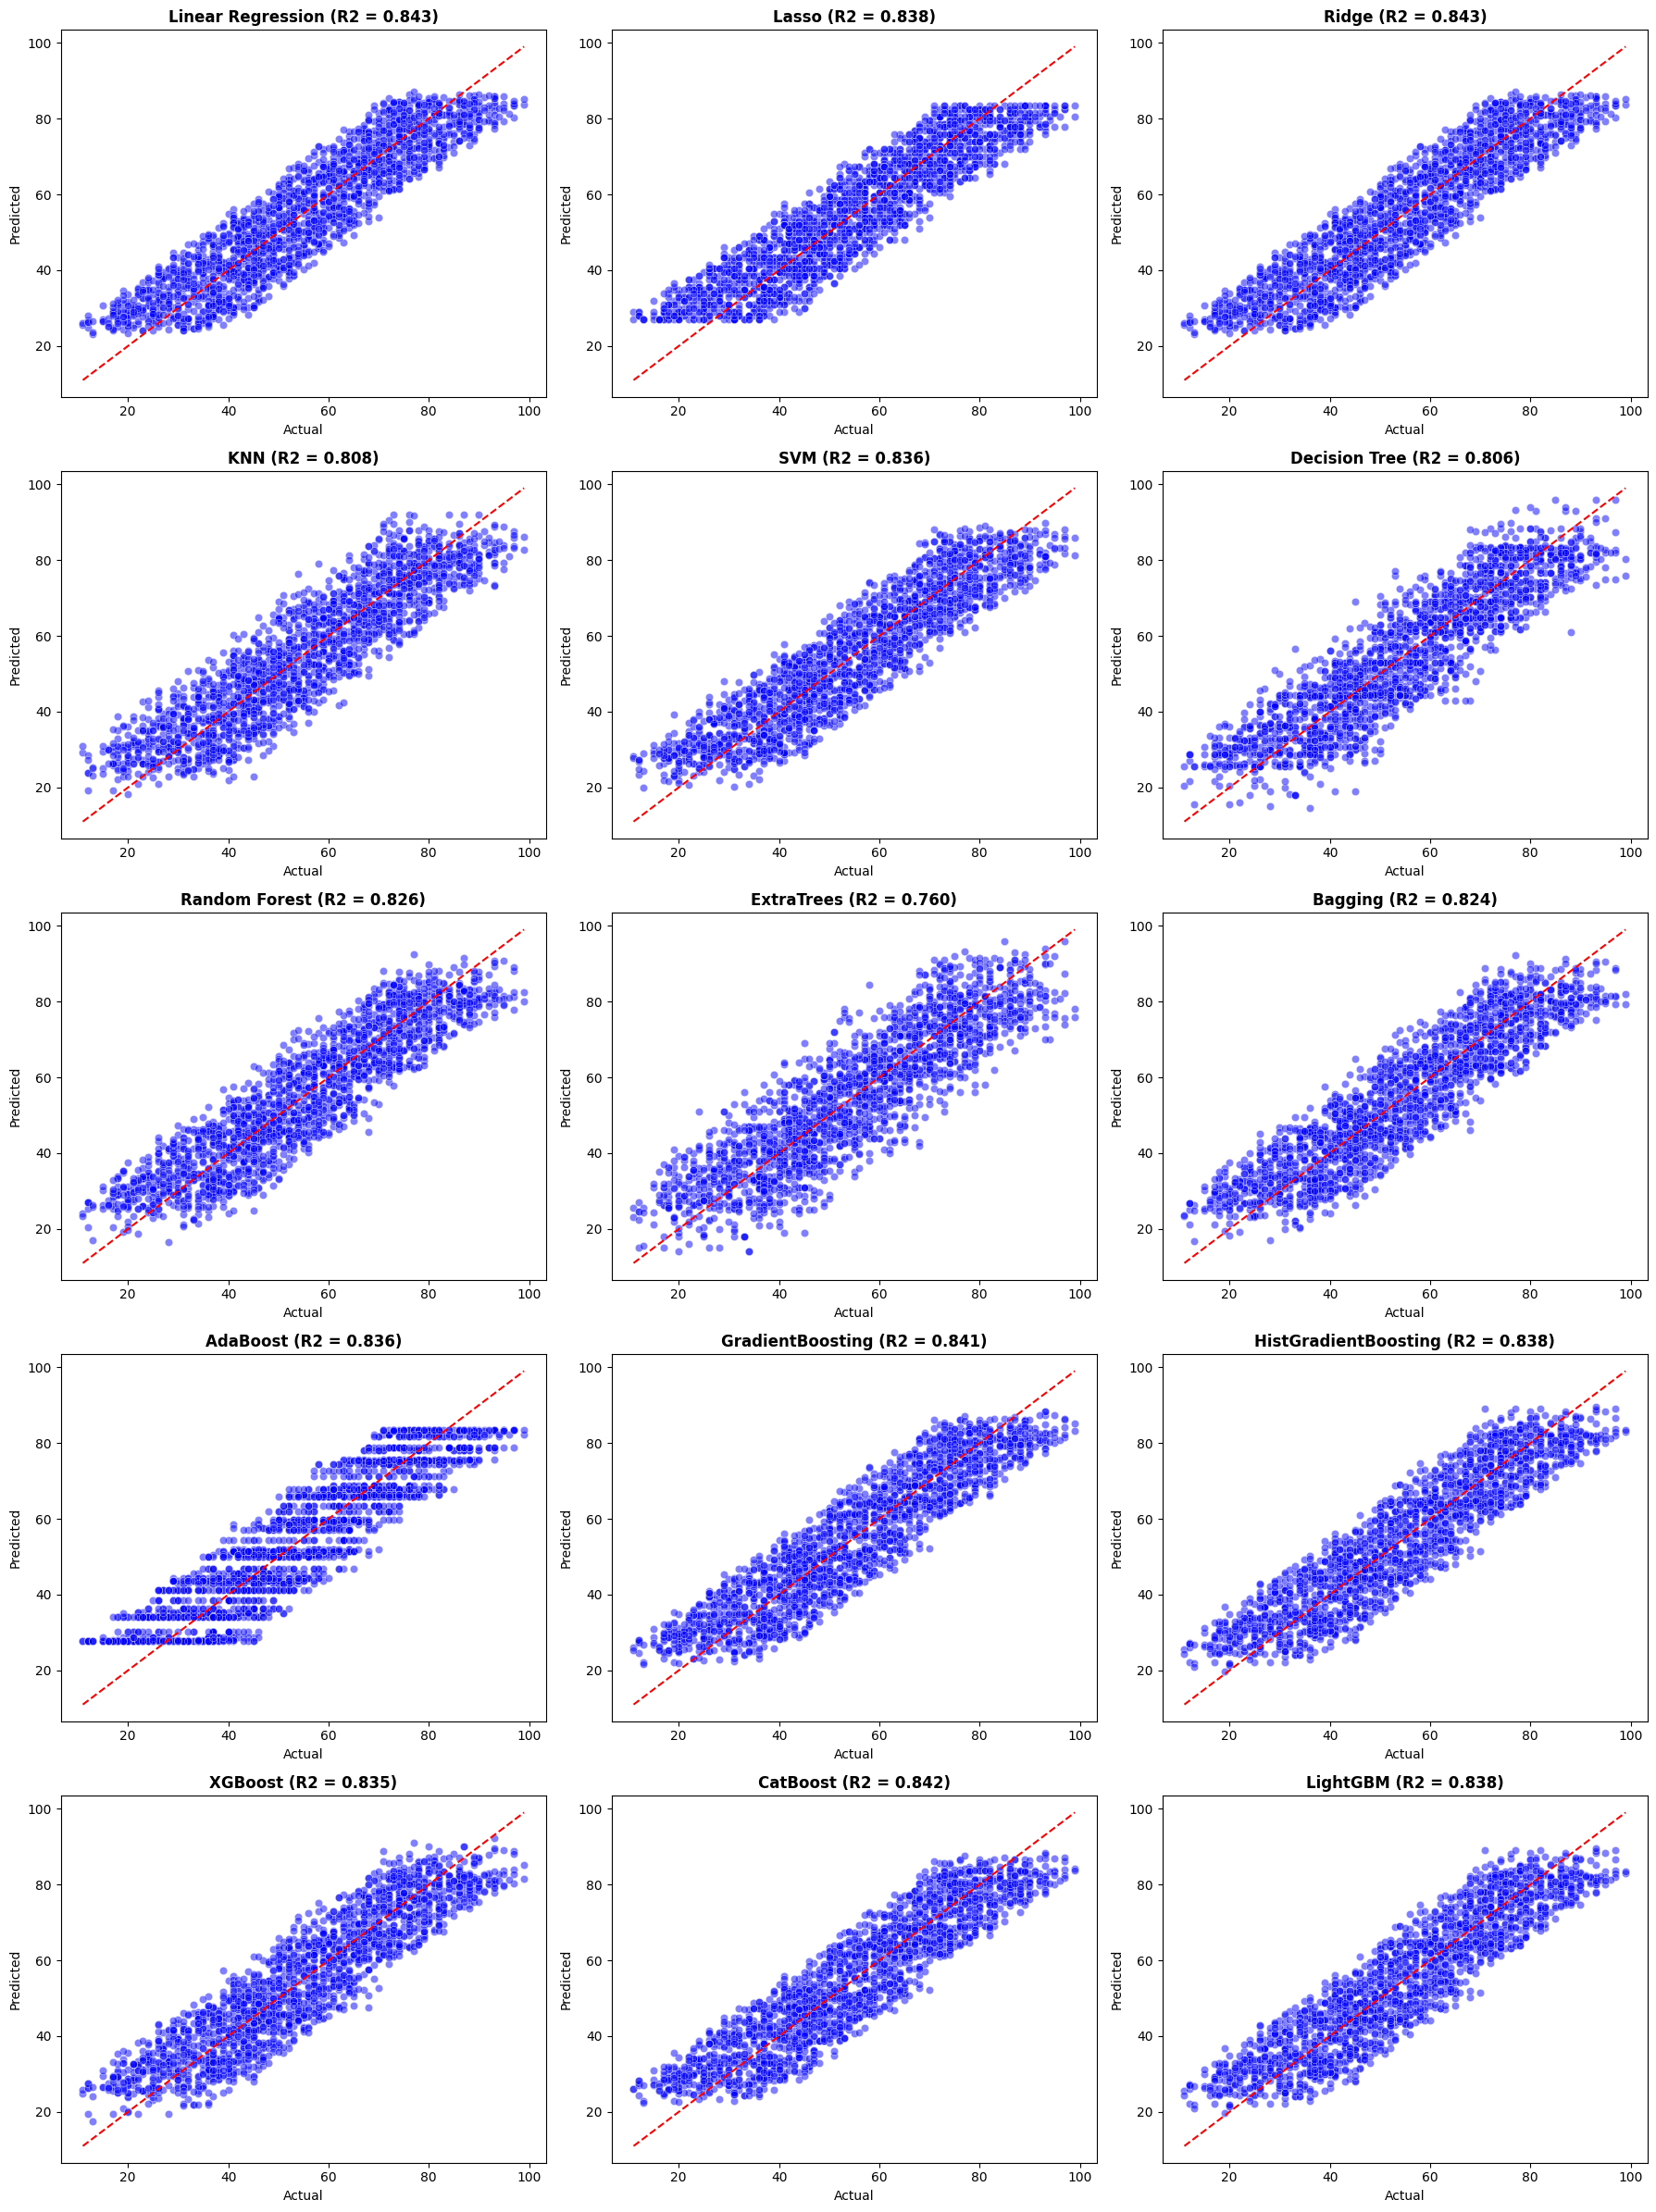

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import r2_score

fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_preds.items()):
  sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=axes[i], color='b')

  low = min(np.min(y_test), np.min(y_pred))
  high = max(np.max(y_test), np.max(y_pred))
  axes[i].plot([low, high], [low, high], color='red', linestyle='--')

  axes[i].set_title(
      f'{name} (R2 = {r2_score(y_test, y_pred):.3f})', fontweight='bold'
  )
  axes[i].set_xlabel('Actual')
  axes[i].set_ylabel('Predicted')

for j in range(len(all_preds), len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='r2', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV R2': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV R2', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Linear Regression": {},
    "Lasso": {"alpha": [0.01, 0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10, 100]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [1, 10, 100]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
base_model = clone(models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'R2': r2_score(y_test, p)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
y_pred = best_model.predict(X_test_scaled)
residuals = np.array(y_test) - y_pred

print('MAE :', mean_absolute_error(y_test, y_pred))
print('MSE :', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2  :', r2_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.5)
low, high = min(np.min(y_test), np.min(y_pred)), max(np.max(y_test), np.max(y_pred))
axes[0].plot([low, high], [low, high], color='red', linestyle='--')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals Plot')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
avg_actual = np.mean(np.abs(y_test))

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- R2 = {r2:.3f}: the model explains about {r2*100:.1f}% of the variation in the target.")
print(f"- MAE = {mae:,.2f}: on average the prediction is off by this amount ({mae/avg_actual*100:.1f}% of the average actual value).")
if rmse > 1.5 * mae:
    print(f"- RMSE ({rmse:,.2f}) is much bigger than MAE, so there are some large errors (outliers) the model misses.")
else:
    print(f"- RMSE ({rmse:,.2f}) is close to MAE, so the errors are fairly even with no big outliers.")
print(f"- Mean residual = {residuals.mean():,.2f}: close to 0 means the model does not systematically over- or under-predict.")
print(f"- Tuning changed R2 from {rows[0]['R2']:.3f} to {rows[1]['R2']:.3f}.")